In [2]:
!pip install pyMPDATA

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyMPDATA]


In [9]:
import numpy as np
import PyMPDATA as mp

In [6]:
from PyMPDATA import ScalarField, VectorField, Options, boundary_conditions as bc
from matplotlib import pyplot as plt

In [29]:
options = Options(n_iters=4, infinite_gauge=True, nonoscillatory=True, third_order_terms=True)
common = {
    'halo': options.n_halo,
    'boundary_conditions': (bc.Periodic(),)
}

In [30]:
Psi = ScalarField(**common, data=(np.exp(-(x:=np.linspace(-2,8,40))**2)))
C = VectorField(**common, data=(np.full(x.size+1, .25),))

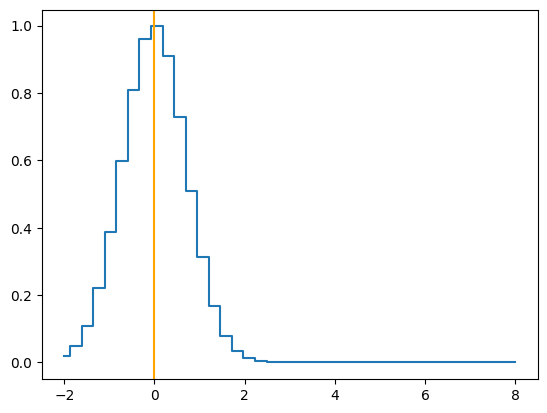

In [31]:
plt.step(x, Psi.get(), where='mid')
plt.axvline(x=0, color='orange')

In [32]:
from PyMPDATA import Stepper, Solver

In [33]:
solver = Solver(advector=C, advectee=Psi, stepper=Stepper(n_dims=1, options=options))
solver.advance(500)

22471.346

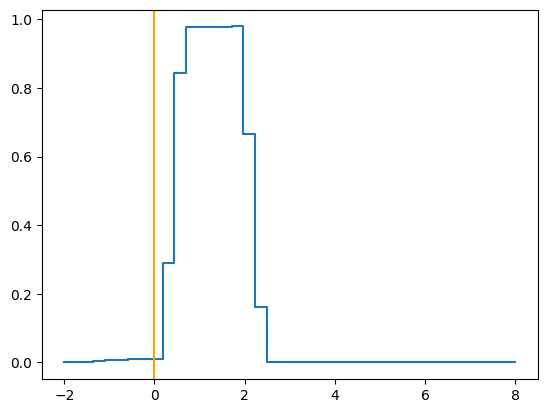

In [34]:
plt.step(x, Psi.get(), where='mid')
plt.axvline(x=0, color='orange')